In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import fisher_exact

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.max_colwidth", 60)

# Auto-resolve repo root whether notebook runs from root or notebooks/
ROOT = Path(".") if (Path("es_results") / "MASTER_ES_panel.parquet").exists() else Path("..")
ES_DIR = ROOT / "es_results"
FIG_DIR = ROOT / "figures"
RES_DIR = ROOT / "results"
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

panel_raw = pd.read_parquet(ES_DIR / "MASTER_ES_panel.parquet")
route_t_raw = pd.read_parquet(ES_DIR / "MASTER_ES_route_t.parquet")
bunk_path = ES_DIR / "MASTER_ES_bunkering.parquet"
bunk = pd.read_parquet(bunk_path) if bunk_path.exists() else pd.DataFrame()

def clean_id(s):
    return s.astype(str).str.split(".").str[0].str.strip()

def add_features(df):
    df = df.copy()
    df["imo_clean"] = clean_id(df["imo_clean"])
    df.loc[df["imo_clean"].isin(["None", "nan", ""]), "imo_clean"] = np.nan
    df["mid_clean"] = clean_id(df["mid"])
    dt = pd.to_datetime(df["year_month"].astype(str) + "-01")
    df["dt"] = dt
    df["t_month"] = (dt.dt.year - 2024) * 12 + (dt.dt.month - 7)  # 0 = 2024-07 .. 23 = 2026-06
    df["quarter"] = dt.dt.to_period("Q").astype(str)
    df["regime"] = pd.Categorical(
        np.where(df["year_month"] < "2025-02", "1_Pre (Jul24-Jan25)",
        np.where(df["year_month"] < "2025-10", "2_Wave1 (Feb-Sep25)", "3_Wave2 (Oct25-Jun26)")),
        categories=["1_Pre (Jul24-Jan25)", "2_Wave1 (Feb-Sep25)", "3_Wave2 (Oct25-Jun26)"],
        ordered=True,
    )
    df["wave1"] = ((df["year_month"] >= "2025-02") & (df["year_month"] < "2025-10")).astype(int)
    df["wave2"] = (df["year_month"] >= "2025-10").astype(int)
    df["cohort"] = np.where(df["ever_dark"] == 1, "Known Dark Fleet",
                   np.where(df["is_star_marine"] == 1, "Star Marine Fleet", "Baseline Un-Sanctioned"))
    return df

def wilson_ci(k, n, z=1.96):
    if n == 0:
        return 0.0, 0.0, 0.0
    p = k / n
    denom = 1.0 + z**2 / n
    center = (p + z**2 / (2.0 * n)) / denom
    half = (z * np.sqrt((p * (1.0 - p) + z**2 / (4.0 * n)) / n)) / denom
    return p * 100.0, max(0.0, (center - half) * 100.0), min(100.0, (center + half) * 100.0)

def fit_clustered(df, formula, cluster_col="vessel_id"):
    tokens = [c.strip() for c in formula.replace("~", "+").replace("*", "+").replace(":", "+").replace("C(", "").replace(")", "").split("+")]
    cols = sorted(set([c for c in tokens if c in df.columns] + [cluster_col]))
    sub = df.dropna(subset=cols).reset_index(drop=True)
    res = smf.ols(formula, data=sub).fit(cov_type="cluster", cov_kwds={"groups": sub[cluster_col]})
    return res, len(sub), sub[cluster_col].nunique()

panel_all = add_features(panel_raw)
route_t = add_features(route_t_raw)

# Attach bunkered_in_dk from panel onto Route T transits
bunk_lookup = panel_all[["block_id", "mmsi", "bunkered_in_dk"]].drop_duplicates(["block_id", "mmsi"])
route_t = route_t.drop(columns=["bunkered_in_dk"], errors="ignore").merge(bunk_lookup, on=["block_id", "mmsi"], how="left")
route_t["bunkered_in_dk"] = route_t["bunkered_in_dk"].fillna(0).astype(int)
route_t["refused_dk_pilot"] = route_t["refused_dk_pilot"].astype(int)

# Exclude physically detained EVENTIN (IMO 9308065, stationary off Sassnitz post-Jan 2025)
detained_rows = int((panel_all["imo_clean"] == "9308065").sum())
active = panel_all[panel_all["imo_clean"] != "9308065"].copy()

rt_eval = route_t[(route_t["is_clean_interior_transit"].astype(int) == 1) & (route_t["gb_max_draught"] >= 11.0)].copy()
rt_nb = rt_eval[rt_eval["direction"] == "Northbound (Baltic Exit)"].copy()
rt_sb = rt_eval[rt_eval["direction"] == "Southbound (Baltic Entry)"].copy()

# Coverage & Hygiene Audit
months_ok = sorted(panel_all["year_month"].unique())
mon_counts = panel_all.groupby("year_month")["mmsi"].count()
low_months = mon_counts[mon_counts < mon_counts.median() * 0.75]

print("=== 24-MONTH EVENT STUDY COVERAGE & HYGIENE AUDIT ===")
print(f"Months completed                  : {len(months_ok)}/24 ({months_ok[0]} -> {months_ok[-1]})")
print(f"Raw Tanker Tracks / Active Tracks : {len(panel_all):,} / {len(active):,} (excluded {detained_rows} detained EVENTIN rows)")
print(f"Unique 7-digit IMOs / MMSIs       : {active['imo_clean'].dropna().nunique():,} / {active['mmsi'].nunique():,}")
print(f"Clean Interior Deep Route T       : {len(rt_eval):,} total ({len(rt_nb):,} Northbound | {len(rt_sb):,} Southbound)")
print(f"Duplicate (block_id, mmsi) rows   : panel={panel_all.duplicated(['block_id','mmsi']).sum()}, route_t={route_t.duplicated(['block_id','mmsi']).sum()}")
print(f"Missing IMO in Northbound Route T : {rt_nb['imo_clean'].isna().sum()}/{len(rt_nb)}")
print(f"Monthly track volume (Med/Min/Max): {int(mon_counts.median())} / {int(mon_counts.min())} ({mon_counts.idxmin()}) / {int(mon_counts.max())} ({mon_counts.idxmax()})")
print("Truncated months detected         :", low_months.to_dict() if not low_months.empty else "None")

=== 24-MONTH EVENT STUDY COVERAGE & HYGIENE AUDIT ===
Months completed                  : 24/24 (2024-07 -> 2026-06)
Raw Tanker Tracks / Active Tracks : 10,694 / 10,675 (excluded 19 detained EVENTIN rows)
Unique 7-digit IMOs / MMSIs       : 2,734 / 3,118
Clean Interior Deep Route T       : 944 total (630 Northbound | 242 Southbound)
Duplicate (block_id, mmsi) rows   : panel=0, route_t=0
Missing IMO in Northbound Route T : 1/630
Monthly track volume (Med/Min/Max): 449 / 400 (2026-02) / 493 (2025-01)
Truncated months detected         : None


In [2]:
# 1. PRE-ENFORCEMENT PARALLEL TRENDS (Jul 2024 - Jan 2025)
print("================ 1. PRE-ENFORCEMENT PARALLEL TRENDS (JUL 2024 - JAN 2025) ================")
pre_act = active[active["regime"] == "1_Pre (Jul24-Jan25)"]
res_pt_sk, n_ptsk, _ = fit_clustered(pre_act, "skagen_stopped_60m ~ ever_dark * t_month + length + is_deep_draught")
res_pt_bk, n_ptbk, _ = fit_clustered(pre_act, "bunkered_in_dk ~ ever_dark * t_month + length + is_deep_draught")
res_pt_pl, n_ptpl, _ = fit_clustered(rt_nb[rt_nb["regime"] == "1_Pre (Jul24-Jan25)"], "refused_dk_pilot ~ ever_shadow_all * t_month + gb_max_draught")

print(f"Skagen Stopping Pre-Trend (ever_dark:t_month) : {res_pt_sk.params['ever_dark:t_month']*100:+.2f} pp/mo (SE={res_pt_sk.bse['ever_dark:t_month']*100:.2f}, p={res_pt_sk.pvalues['ever_dark:t_month']:.4f}) | N={n_ptsk:,}")
print(f"DK Bunkering Pre-Trend    (ever_dark:t_month) : {res_pt_bk.params['ever_dark:t_month']*100:+.2f} pp/mo (SE={res_pt_bk.bse['ever_dark:t_month']*100:.2f}, p={res_pt_bk.pvalues['ever_dark:t_month']:.4f}) | N={n_ptbk:,}")
print(f"Pilotage Refusal Pre-Trend(shadow:t_month)    : {res_pt_pl.params['ever_shadow_all:t_month']*100:+.2f} pp/mo (SE={res_pt_pl.bse['ever_shadow_all:t_month']*100:.2f}, p={res_pt_pl.pvalues['ever_shadow_all:t_month']:.4f}) | N={n_ptpl:,}")

# 2. 3-REGIME CLUSTER-ROBUST DiD (Standard Errors Clustered by Vessel)
print("\n================ 2. 3-REGIME CLUSTER-ROBUST DiD (ACTIVE FLEET) ================")
res_sk_did, n_sk, cl_sk = fit_clustered(active, "skagen_stopped_60m ~ ever_dark * wave1 + ever_dark * wave2")
res_sk_ctl, n_skc, cl_skc = fit_clustered(active, "skagen_stopped_60m ~ ever_dark * wave1 + ever_dark * wave2 + is_deep_draught + length")
res_bk_did, n_bk, cl_bk = fit_clustered(active, "bunkered_in_dk ~ ever_dark * wave1 + ever_dark * wave2 + is_deep_draught + length")
res_pl_did, n_pl, cl_pl = fit_clustered(rt_nb, "refused_dk_pilot ~ ever_shadow_all * wave1 + ever_shadow_all * wave2 + gb_max_draught")

print(f"A1. Skagen Stopping DiD — Baseline (N={n_sk:,}, Vessels={cl_sk:,}):")
for t in ["ever_dark", "ever_dark:wave1", "ever_dark:wave2"]:
    print(f"    {t:18s}: {res_sk_did.params[t]*100:+6.2f} pp (SE={res_sk_did.bse[t]*100:.2f}, p={res_sk_did.pvalues[t]:.5f})")

print(f"\nA2. Skagen Stopping DiD — With Size/Draught Controls (N={n_skc:,}, Vessels={cl_skc:,}):")
for t in ["ever_dark", "ever_dark:wave1", "ever_dark:wave2"]:
    print(f"    {t:18s}: {res_sk_ctl.params[t]*100:+6.2f} pp (SE={res_sk_ctl.bse[t]*100:.2f}, p={res_sk_ctl.pvalues[t]:.5f})")

print(f"\nB.  Danish Bunkering DiD (N={n_bk:,}, Vessels={cl_bk:,}):")
for t in ["ever_dark", "ever_dark:wave1", "ever_dark:wave2"]:
    print(f"    {t:18s}: {res_bk_did.params[t]*100:+6.2f} pp (SE={res_bk_did.bse[t]*100:.2f}, p={res_bk_did.pvalues[t]:.5f})")

print(f"\nC.  Northbound Pilotage Refusal DiD (All Shadow vs Baseline, N={n_pl:,}, Vessels={cl_pl:,}):")
for t in ["ever_shadow_all", "ever_shadow_all:wave1", "ever_shadow_all:wave2"]:
    print(f"    {t:22s}: {res_pl_did.params[t]*100:+6.2f} pp (SE={res_pl_did.bse[t]*100:.2f}, p={res_pl_did.pvalues[t]:.5f})")

# 3. WITHIN-VESSEL FIXED EFFECTS (Repeat Northbound Hulls)
print("\n================ 3. VESSEL FIXED EFFECTS (REPEAT HULLS ONLY) ================")
rep_v = rt_nb.groupby("vessel_id").filter(lambda g: len(g) >= 2).copy()
res_fe, n_fe, cl_fe = fit_clustered(rep_v, "refused_dk_pilot ~ wave1 + wave2 + ever_shadow_all:wave1 + ever_shadow_all:wave2 + C(vessel_id)")
print(f"Repeat Northbound Hulls: {cl_fe} ({n_fe} transits)")
for t in ["wave1", "wave2", "ever_shadow_all:wave1", "ever_shadow_all:wave2"]:
    if t in res_fe.params:
        print(f"    {t:22s}: {res_fe.params[t]*100:+6.2f} pp (SE={res_fe.bse[t]*100:.2f}, p={res_fe.pvalues[t]:.5f})")

switchers = rep_v.groupby("vessel_id").filter(lambda g: g["refused_dk_pilot"].nunique() == 2)
print(f"\nHulls switching between taking & refusing pilots: {switchers['vessel_id'].nunique()}")
display(switchers.sort_values(["vessel_id", "year_month"])[
    ["vessel_id", "year_month", "name", "mid_clean", "ever_dark", "is_star_marine", "gb_max_draught", "refused_dk_pilot", "destinations"]
])

================ 1. PRE-ENFORCEMENT PARALLEL TRENDS (JUL 2024 - JAN 2025) ================
Skagen Stopping Pre-Trend (ever_dark:t_month) : -1.25 pp/mo (SE=0.80, p=0.1150) | N=3,221
DK Bunkering Pre-Trend    (ever_dark:t_month) : -0.15 pp/mo (SE=0.28, p=0.5901) | N=3,221
Pilotage Refusal Pre-Trend(shadow:t_month)    : +2.93 pp/mo (SE=2.02, p=0.1457) | N=179

================ 2. 3-REGIME CLUSTER-ROBUST DiD (ACTIVE FLEET) ================
A1. Skagen Stopping DiD — Baseline (N=10,675, Vessels=2,801):
    ever_dark         :  -1.11 pp (SE=2.08, p=0.59252)
    ever_dark:wave1   :  -5.73 pp (SE=2.38, p=0.01598)
    ever_dark:wave2   :  -8.60 pp (SE=2.25, p=0.00013)

A2. Skagen Stopping DiD — With Size/Draught Controls (N=10,654, Vessels=2,798):
    ever_dark         :  -5.42 pp (SE=2.16, p=0.01219)
    ever_dark:wave1   :  -5.69 pp (SE=2.35, p=0.01546)
    ever_dark:wave2   :  -8.77 pp (SE=2.25, p=0.00010)

B.  Danish Bunkering DiD (N=10,654, Vessels=2,798):
    ever_dark         :  -6.43 pp 

,vessel_id,year_month,name,mid_clean,ever_dark,is_star_marine,gb_max_draught,refused_dk_pilot,destinations
301,9230505,2024-12,NEW LEGEND,636,0,0,15.0,0,INDIA FOR ORDERS
622,9230505,2025-06,NEW LEGEND,636,0,0,12.5,1,ALIAGA
729,9230505,2025-08,NEW LEGEND,636,0,0,12.6,1,"ALIAGA,TURKEY"
1113,9230505,2026-03,NEW LEGEND,636,0,0,14.7,1,EGSUZ FOR ORDERS
383,9271573,2025-02,ADEBOMI,352,1,0,14.6,0,IN NML
602,9271573,2025-06,ADEBOMI,352,1,0,12.5,0,TR ALI
1291,9271573,2026-06,VIXENA,667,1,0,14.5,1,ALIAGA TURKEY
76,9285835,2024-08,SEA FIDELITY,518,1,0,14.3,0,KOCHIN
270,9285835,2024-12,SEA FIDELITY,334,1,0,14.9,1,GIBRALTAR
739,9330472,2025-08,THORIN,667,1,0,14.7,1,PORT SAID


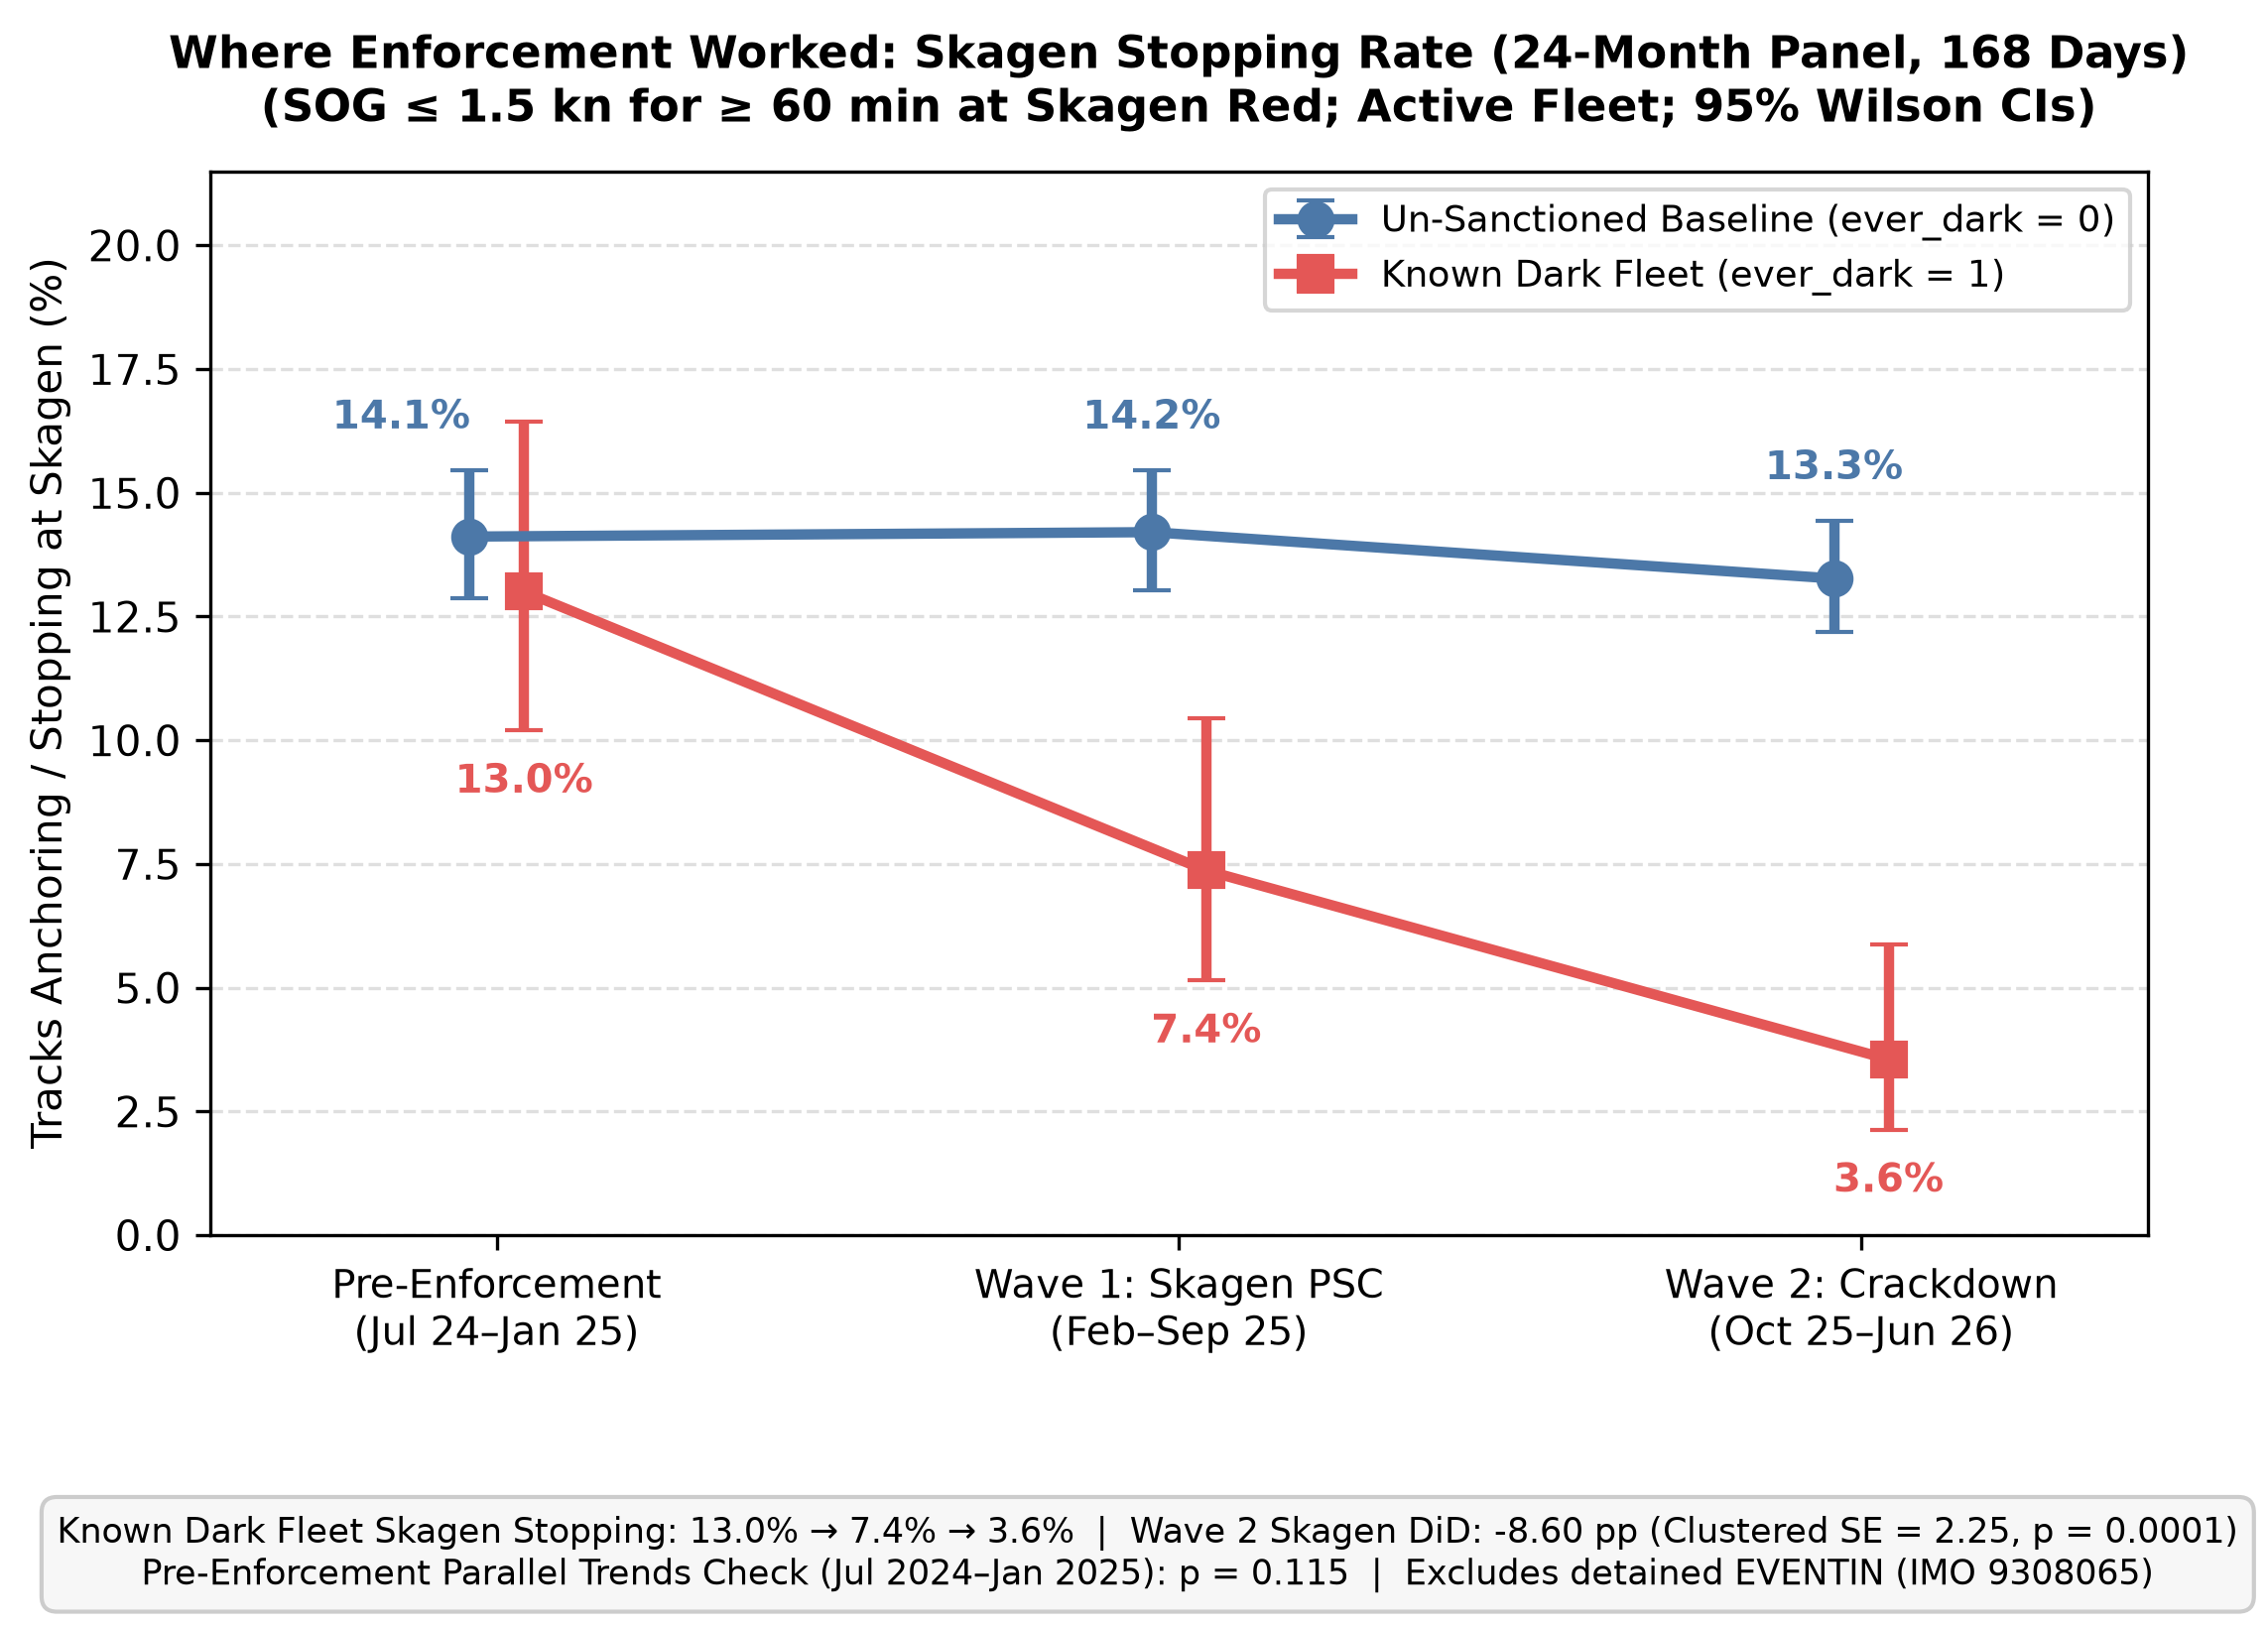

Saved -> figures\fig1_skagen_enforcement.png


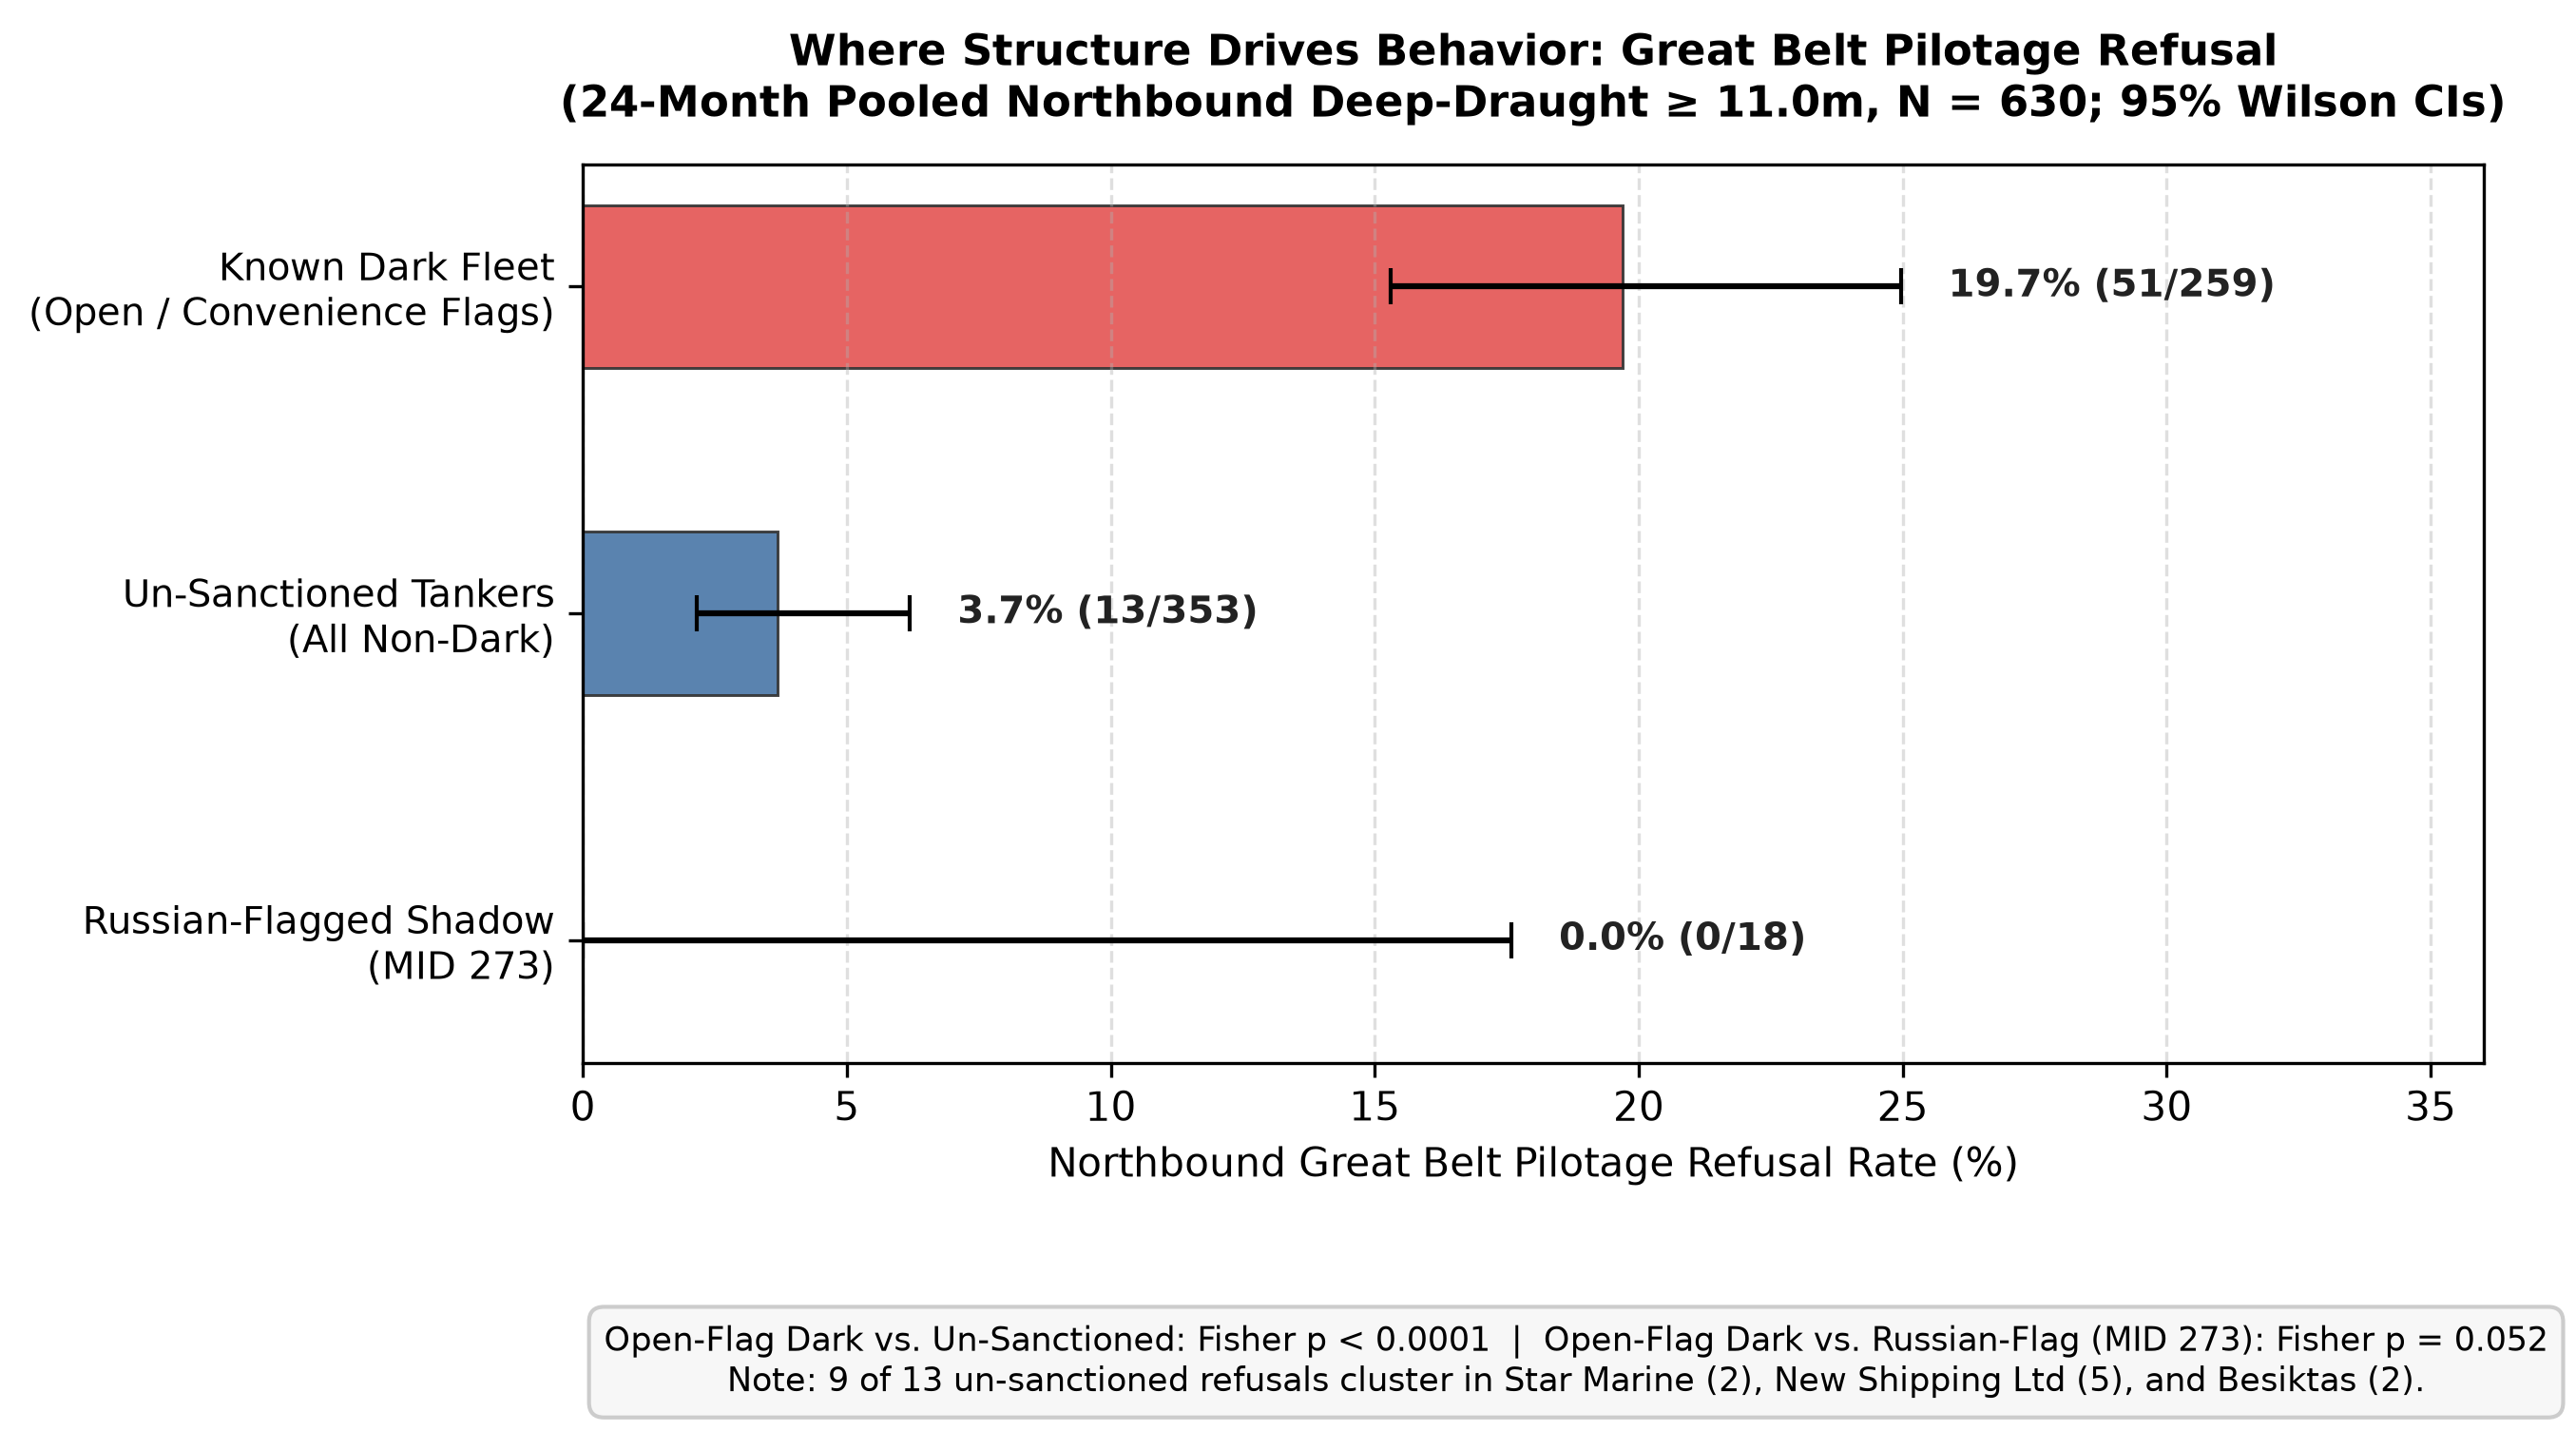

Saved -> figures\fig2_pilotage_architecture.png


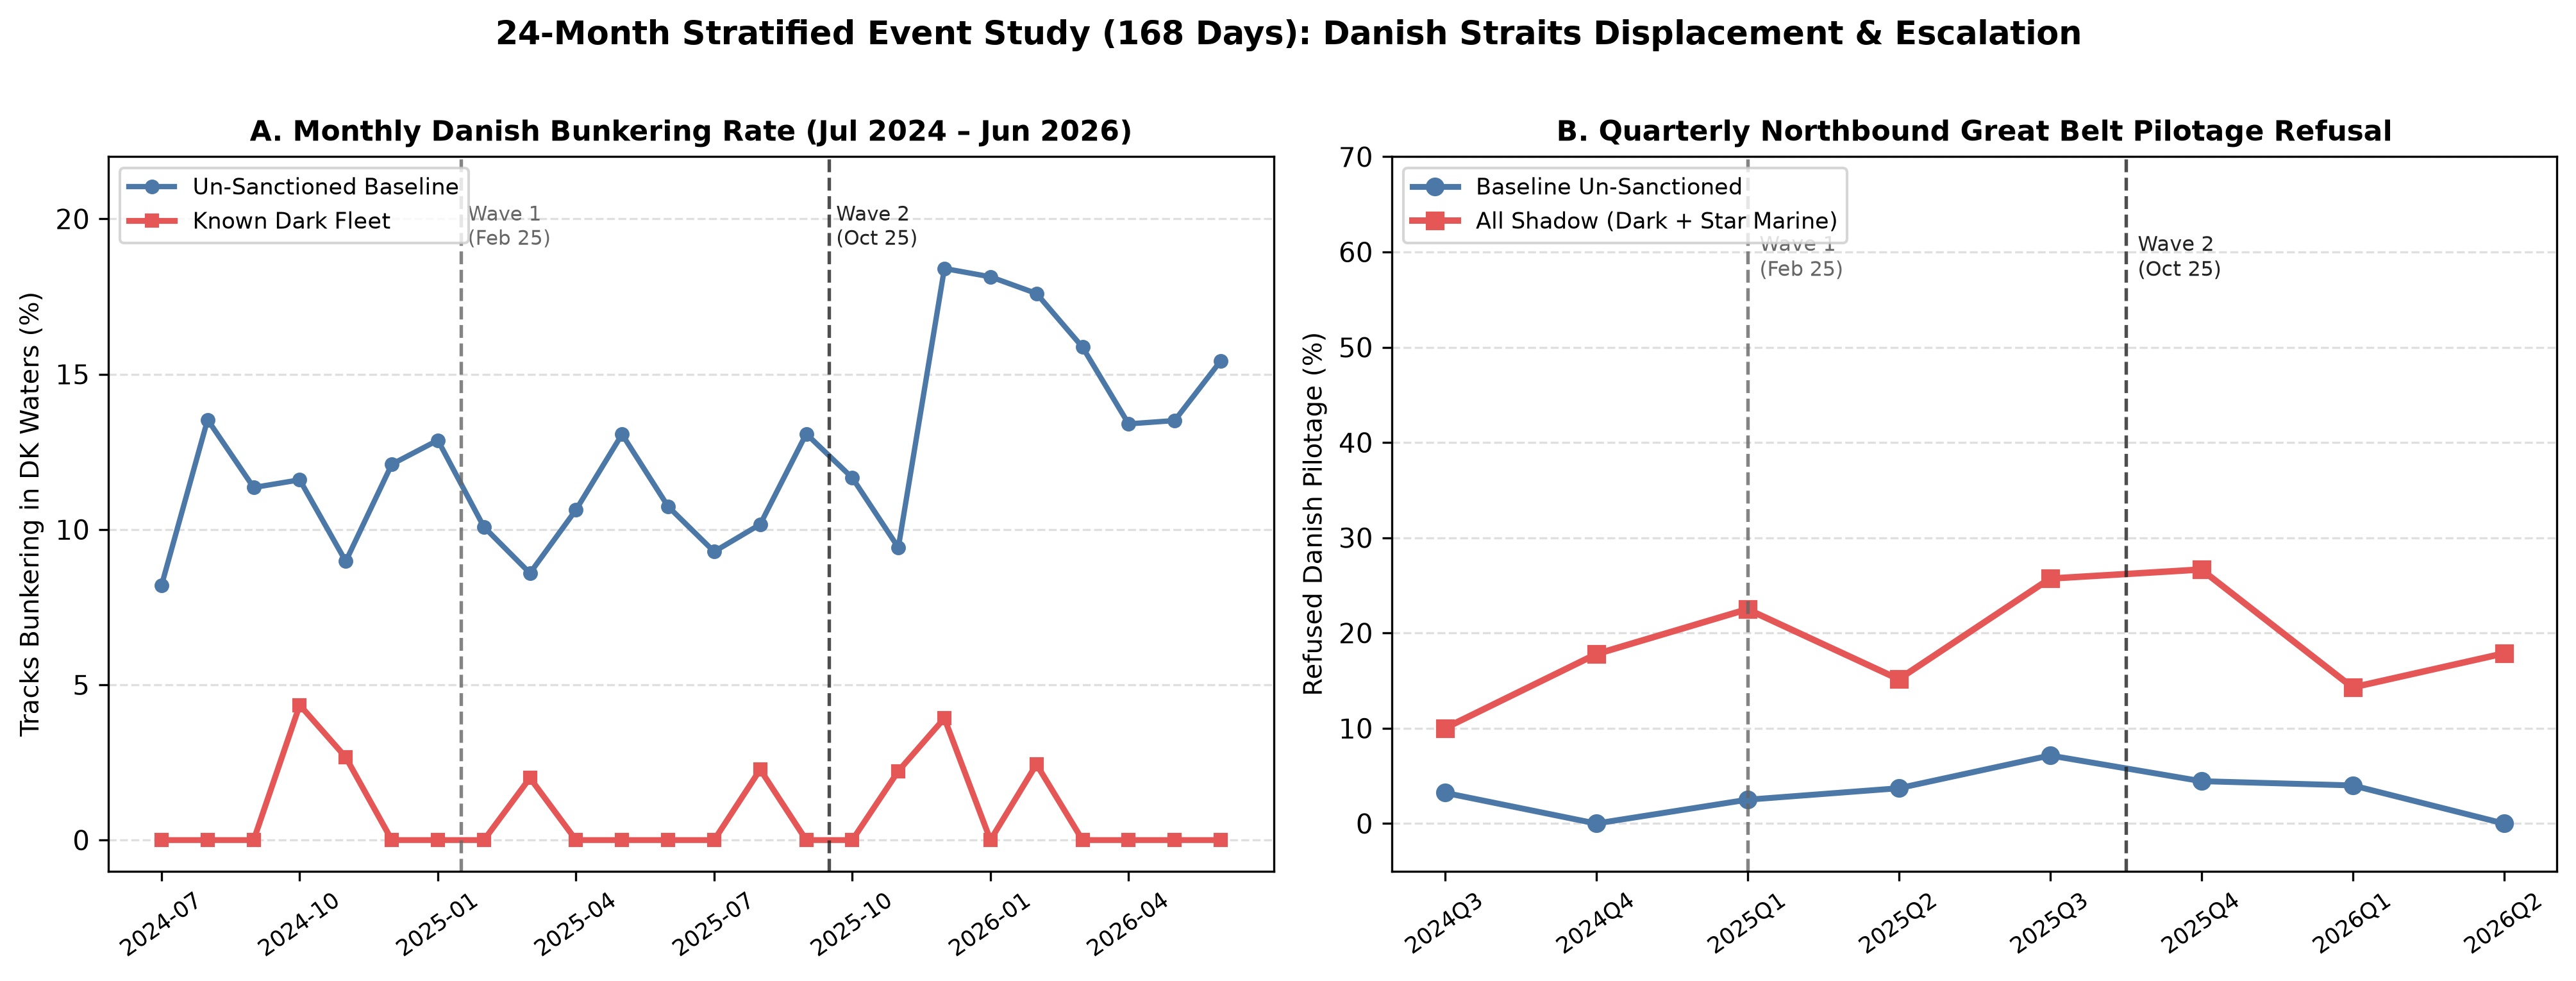

Saved -> figures\fig3_event_study_24m.png


In [3]:
regimes = ["1_Pre (Jul24-Jan25)", "2_Wave1 (Feb-Sep25)", "3_Wave2 (Oct25-Jun26)"]
reg_labels = ["Pre-Enforcement\n(Jul 24–Jan 25)", "Wave 1: Skagen PSC\n(Feb–Sep 25)", "Wave 2: Crackdown\n(Oct 25–Jun 26)"]
x_r = np.arange(len(regimes))

# ==============================================================================
# FIGURE 1: WHERE ENFORCEMENT WORKED (3-REGIME SKAGEN STOPPING)
# ==============================================================================
fig, ax = plt.subplots(figsize=(8.4, 5.5), dpi=300)
offsets = {0: -0.04, 1: 0.04}
sk_dark_vals = []

for dark_val, lbl, col, mk in [
    (0, "Un-Sanctioned Baseline (ever_dark = 0)", "#4c78a8", "o"),
    (1, "Known Dark Fleet (ever_dark = 1)", "#e45756", "s"),
]:
    sub = active[active["ever_dark"] == dark_val]
    ys, lo_err, hi_err = [], [], []
    for r in regimes:
        sr = sub[sub["regime"] == r]
        p, lo, hi = wilson_ci(int(sr["skagen_stopped_60m"].sum()), len(sr))
        ys.append(p); lo_err.append(p - lo); hi_err.append(hi - p)
    if dark_val == 1:
        sk_dark_vals = ys

    x_plot = x_r + offsets[dark_val]
    ax.errorbar(x_plot, ys, yerr=[lo_err, hi_err], marker=mk, markersize=8,
                linewidth=2.5, capsize=4.5, color=col, label=lbl)
    for idx_i, (xi, yi, lo_e, hi_e) in enumerate(zip(x_plot, ys, lo_err, hi_err)):
        if dark_val == 0:
            x_txt = xi - 0.10 if idx_i == 0 else xi
            ax.text(x_txt, yi + hi_e + 0.65, f"{yi:.1f}%", ha="center", va="bottom", fontsize=9.5, fontweight="bold", color=col)
        else:
            ax.text(xi, yi - lo_e - 0.65, f"{yi:.1f}%", ha="center", va="top", fontsize=9.5, fontweight="bold", color=col)

ax.set_title("Where Enforcement Worked: Skagen Stopping Rate (24-Month Panel, 168 Days)\n(SOG ≤ 1.5 kn for ≥ 60 min at Skagen Red; Active Fleet; 95% Wilson CIs)", fontsize=10.8, fontweight="bold", pad=12)
ax.set_xticks(x_r); ax.set_xticklabels(reg_labels, fontsize=9.5)
ax.set_xlim(-0.42, 2.42); ax.set_ylim(0, 21.5)
ax.set_ylabel("Tracks Anchoring / Stopping at Skagen (%)", fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(loc="upper right", fontsize=8.8, frameon=True)

w2_eff = res_sk_did.params["ever_dark:wave2"] * 100
w2_se  = res_sk_did.bse["ever_dark:wave2"] * 100
w2_p   = res_sk_did.pvalues["ever_dark:wave2"]
pt_p   = res_pt_sk.pvalues["ever_dark:t_month"]

fig.subplots_adjust(bottom=0.23)
fig.text(
    0.5, 0.035,
    f"Known Dark Fleet Skagen Stopping: {sk_dark_vals[0]:.1f}% → {sk_dark_vals[1]:.1f}% → {sk_dark_vals[2]:.1f}%  |  "
    f"Wave 2 Skagen DiD: {w2_eff:+.2f} pp (Clustered SE = {w2_se:.2f}, p = {w2_p:.4f})\n"
    f"Pre-Enforcement Parallel Trends Check (Jul 2024–Jan 2025): p = {pt_p:.3f}  |  Excludes detained EVENTIN (IMO 9308065)",
    ha="center", va="center", fontsize=8.3,
    bbox=dict(boxstyle="round,pad=0.45", facecolor="#f7f7f7", edgecolor="#cccccc")
)

out_f1 = FIG_DIR / "fig1_skagen_enforcement.png"
plt.savefig(out_f1, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {out_f1}")

# ==============================================================================
# FIGURE 2: WHERE STRUCTURE DRIVES BEHAVIOR (GREAT BELT PILOTAGE REFUSAL)
# ==============================================================================
fig, ax = plt.subplots(figsize=(8.6, 5.0), dpi=300)

rt_s = rt_nb.copy()
rt_s["struct_grp"] = np.where(
    rt_s["ever_dark"] == 0, "Un-Sanctioned Tankers\n(All Non-Dark)",
    np.where(rt_s["mid_clean"] == "273", "Russian-Flagged Shadow\n(MID 273)", "Known Dark Fleet\n(Open / Convenience Flags)")
)

order = [
    ("Russian-Flagged Shadow\n(MID 273)", "#72b7b2"),
    ("Un-Sanctioned Tankers\n(All Non-Dark)", "#4c78a8"),
    ("Known Dark Fleet\n(Open / Convenience Flags)", "#e45756"),
]

y_pos = np.arange(len(order))
means, lo_errs, hi_errs, labels_n, colors, counts_dict = [], [], [], [], [], {}
for grp_name, col in order:
    sub = rt_s[rt_s["struct_grp"] == grp_name]
    k, n = int(sub["refused_dk_pilot"].sum()), len(sub)
    counts_dict[grp_name] = (k, n)
    p, lo, hi = wilson_ci(k, n)
    means.append(p); lo_errs.append(p - lo); hi_errs.append(hi - p)
    labels_n.append(f"{p:.1f}% ({k}/{n})")
    colors.append(col)

ax.barh(y_pos, means, xerr=[lo_errs, hi_errs], height=0.50, color=colors, alpha=0.92,
        capsize=4.5, edgecolor="#333333", linewidth=0.7)
for yi, m, hi_e, txt in zip(y_pos, means, hi_errs, labels_n):
    ax.text(m + hi_e + 0.9, yi, txt, va="center", ha="left", fontsize=9.5, fontweight="bold", color="#222222")

k_dk, n_dk = counts_dict["Known Dark Fleet\n(Open / Convenience Flags)"]
k_un, n_un = counts_dict["Un-Sanctioned Tankers\n(All Non-Dark)"]
k_ru, n_ru = counts_dict["Russian-Flagged Shadow\n(MID 273)"]
_, p_dk_ru = fisher_exact([[k_dk, n_dk - k_dk], [k_ru, n_ru - k_ru]])

ax.set_yticks(y_pos); ax.set_yticklabels([o[0] for o in order], fontsize=9.5)
ax.set_xlim(0, 36)
ax.set_xlabel("Northbound Great Belt Pilotage Refusal Rate (%)", fontsize=10)
ax.set_title("Where Structure Drives Behavior: Great Belt Pilotage Refusal\n(24-Month Pooled Northbound Deep-Draught ≥ 11.0m, N = 630; 95% Wilson CIs)", fontsize=10.8, fontweight="bold", pad=12)
ax.grid(axis="x", linestyle="--", alpha=0.4)

fig.subplots_adjust(bottom=0.25)
fig.text(
    0.53, 0.04,
    f"Open-Flag Dark vs. Un-Sanctioned: Fisher p < 0.0001  |  Open-Flag Dark vs. Russian-Flag (MID 273): Fisher p = {p_dk_ru:.3f}\n"
    f"Note: 9 of {k_un} un-sanctioned refusals cluster in Star Marine (2), New Shipping Ltd (5), and Besiktas (2).",
    ha="center", va="center", fontsize=8.4,
    bbox=dict(boxstyle="round,pad=0.45", facecolor="#f7f7f7", edgecolor="#cccccc")
)

out_f2 = FIG_DIR / "fig2_pilotage_architecture.png"
plt.savefig(out_f2, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {out_f2}")

# ==============================================================================
# FIGURE 3 (SUPPLEMENTARY): MONTHLY BUNKERING & QUARTERLY PILOTAGE SERIES
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0), dpi=300)

b_piv = (
    active.groupby(["year_month", "ever_dark"], as_index=False)["bunkered_in_dk"]
    .mean().pivot(index="year_month", columns="ever_dark", values="bunkered_in_dk")
    .reindex(months_ok) * 100
)
x_m = np.arange(len(months_ok))
axes[0].plot(x_m, b_piv[0], marker="o", markersize=4.5, linewidth=2.0, color="#4c78a8", label="Un-Sanctioned Baseline")
axes[0].plot(x_m, b_piv[1], marker="s", markersize=4.5, linewidth=2.2, color="#e45756", label="Known Dark Fleet")
for m_tag, lbl, col in [("2025-02", "Wave 1\n(Feb 25)", "#666666"), ("2025-10", "Wave 2\n(Oct 25)", "#222222")]:
    idx_m = months_ok.index(m_tag)
    axes[0].axvline(idx_m - 0.5, linestyle="--", linewidth=1.3, color=col, alpha=0.8)
    axes[0].text(idx_m - 0.35, 20.5, lbl, fontsize=7.5, color=col, va="top")
axes[0].set_title("A. Monthly Danish Bunkering Rate (Jul 2024 – Jun 2026)", fontsize=10.5, fontweight="bold")
axes[0].set_xticks(x_m[::3]); axes[0].set_xticklabels([months_ok[i] for i in x_m[::3]], rotation=35, fontsize=8.5)
axes[0].set_ylabel("Tracks Bunkering in DK Waters (%)", fontsize=9.5)
axes[0].set_ylim(-1, 22); axes[0].grid(axis="y", linestyle="--", alpha=0.4); axes[0].legend(loc="upper left", fontsize=8.5)

quarters = sorted(rt_nb["quarter"].unique())
rt_nb_q = rt_nb.copy()
rt_nb_q["shadow_grp"] = np.where(rt_nb_q["ever_shadow_all"] == 1, "All Shadow (Dark + SM)", "Baseline Un-Sanctioned")
p_piv = rt_nb_q.groupby(["quarter", "shadow_grp"], as_index=False)["refused_dk_pilot"].mean().pivot(
    index="quarter", columns="shadow_grp", values="refused_dk_pilot"
).reindex(quarters) * 100
x_q = np.arange(len(quarters))
axes[1].plot(x_q, p_piv["Baseline Un-Sanctioned"], marker="o", markersize=6, linewidth=2.2, color="#4c78a8", label="Baseline Un-Sanctioned")
axes[1].plot(x_q, p_piv["All Shadow (Dark + SM)"], marker="s", markersize=6, linewidth=2.4, color="#e45756", label="All Shadow (Dark + Star Marine)")
for q_tag, offset, lbl, col in [("2025Q1", 0.0, "Wave 1\n(Feb 25)", "#666666"), ("2025Q4", -0.5, "Wave 2\n(Oct 25)", "#222222")]:
    idx_q = quarters.index(q_tag)
    axes[1].axvline(idx_q + offset, linestyle="--", linewidth=1.3, color=col, alpha=0.8)
    axes[1].text(idx_q + offset + 0.08, 62, lbl, fontsize=7.8, color=col, va="top")
axes[1].set_title("B. Quarterly Northbound Great Belt Pilotage Refusal", fontsize=10.5, fontweight="bold")
axes[1].set_xticks(x_q); axes[1].set_xticklabels(quarters, rotation=35, fontsize=8.5)
axes[1].set_ylabel("Refused Danish Pilotage (%)", fontsize=9.5)
axes[1].set_ylim(-5, 70); axes[1].grid(axis="y", linestyle="--", alpha=0.4); axes[1].legend(loc="upper left", fontsize=8.5)

fig.suptitle("24-Month Stratified Event Study (168 Days): Danish Straits Displacement & Escalation", fontsize=12.2, fontweight="bold", y=1.01)
plt.tight_layout()
out_f3 = FIG_DIR / "fig3_event_study_24m.png"
plt.savefig(out_f3, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> {out_f3}")

In [4]:
def summarize_pilot(df, label):
    n, k = len(df), int(df["refused_dk_pilot"].sum())
    p, lo, hi = wilson_ci(k, n)
    return {
        "Cohort": label,
        "Transits": n,
        "Refusals": k,
        "Refusal_%": round(p, 2),
        "Compliance_%": round(100.0 - p, 2),
        "Refusal_95CI": f"[{lo:.2f}, {hi:.2f}]",
    }

print("=== 1. DIRECTIONAL PLACEBO CHECK (CLEAN INTERIOR ROUTE T >= 11.0m) ===")
placebo_tbl = pd.DataFrame([
    summarize_pilot(rt_nb, "All Northbound (Baltic Exit)"),
    summarize_pilot(rt_sb, "All Southbound (Baltic Entry)"),
    summarize_pilot(rt_nb[rt_nb["ever_dark"] == 0], "Un-Sanctioned NB (ever_dark = 0)"),
    summarize_pilot(rt_sb[rt_sb["ever_dark"] == 0], "Un-Sanctioned SB (ever_dark = 0)"),
    summarize_pilot(rt_nb[rt_nb["ever_shadow_all"] == 0], "Un-Sanctioned NB (excl. Star Marine)"),
    summarize_pilot(rt_sb[rt_sb["ever_shadow_all"] == 0], "Un-Sanctioned SB (excl. Star Marine)"),
])
print(placebo_tbl.to_string(index=False))

_, p_all_dir = fisher_exact([
    [int(rt_nb["refused_dk_pilot"].sum()), len(rt_nb) - int(rt_nb["refused_dk_pilot"].sum())],
    [int(rt_sb["refused_dk_pilot"].sum()), len(rt_sb) - int(rt_sb["refused_dk_pilot"].sum())]
])
u_nb, u_sb = rt_nb[rt_nb["ever_dark"] == 0], rt_sb[rt_sb["ever_dark"] == 0]
_, p_uns_dir = fisher_exact([
    [int(u_nb["refused_dk_pilot"].sum()), len(u_nb) - int(u_nb["refused_dk_pilot"].sum())],
    [int(u_sb["refused_dk_pilot"].sum()), len(u_sb) - int(u_sb["refused_dk_pilot"].sum())]
])
print(f"\nFisher Exact (All NB vs SB):                p = {p_all_dir:.6f}")
print(f"Fisher Exact (Un-Sanctioned NB vs SB):      p = {p_uns_dir:.6f}")

# Structural breakdown by direction (including Open-Flag Dark SB check)
rt_dir = rt_eval[rt_eval["direction"].isin(["Northbound (Baltic Exit)", "Southbound (Baltic Entry)"])].copy()
rt_dir["struct_grp"] = np.where(
    rt_dir["ever_dark"] == 0, "Un-Sanctioned",
    np.where(rt_dir["mid_clean"] == "273", "Russian-Flagged Dark (MID 273)", "Open-Flag Dark Fleet")
)
print("\n=== 2. STRUCTURAL COHORTS BY DIRECTION ===")
print(rt_dir.groupby(["struct_grp", "direction"]).agg(
    transits=("mmsi", "count"),
    refusals=("refused_dk_pilot", "sum"),
    refusal_pct=("refused_dk_pilot", lambda s: round(s.mean() * 100, 1)),
    med_draught=("gb_max_draught", "median"),
))

# Flagged Corporate Clusters: Northbound vs. Southbound (Deep & All Draughts)
COMPANY_IMOS = {
    "New Shipping Ltd (Athens, IG P&I)": {"9230505", "9274812", "9230517"},
    "Besiktas Likid Tasimacilik (Turkey, IG P&I)": {"9396787", "9354258"},
    "Executive Ship Mgmt (AFRAMAX RIO)": {"9273844"},
}
SM_POST_NAMES = {"BYZANTIUM", "MIDEA", "KNOSSOS", "NYXORA", "GATTACA", "NEPHIRA", "HELION", "MINOS", "NYSEA", "ACHERON"}

rt_corp = route_t[
    (route_t["is_clean_interior_transit"].astype(int) == 1) &
    (route_t["direction"].isin(["Northbound (Baltic Exit)", "Southbound (Baltic Entry)"]))
].copy()
rt_corp["name_upper"] = rt_corp["name"].fillna("").str.upper().str.strip()

def assign_company(row):
    for comp, imos in COMPANY_IMOS.items():
        if row["imo_clean"] in imos:
            return comp
    if row.get("is_star_marine", 0) == 1:
        return "Star Marine Mgmt (Post-Acquisition)" if row["name_upper"] in SM_POST_NAMES else "Star Marine Hulls (Pre-Acquisition)"
    return None

rt_corp["flagged_company"] = rt_corp.apply(assign_company, axis=1)
sub_corp = rt_corp[rt_corp["flagged_company"].notna()].copy()

print("\n=== 3. FLAGGED CORPORATE CLUSTERS (CLEAN INTERIOR, >= 11.0m) ===")
display(sub_corp[sub_corp["gb_max_draught"] >= 11.0].groupby(["flagged_company", "direction"]).agg(
    transits=("mmsi", "count"),
    refusals=("refused_dk_pilot", "sum"),
    refusal_pct=("refused_dk_pilot", lambda s: round(s.mean() * 100, 1)),
    med_draught=("gb_max_draught", "median"),
    vessels=("name_upper", lambda s: ", ".join(sorted(set(s)))),
))
print(f"Total Southbound Transits (Any Draught) by Flagged Companies: {(sub_corp['direction'] == 'Southbound (Baltic Entry)').sum()}")

=== 1. DIRECTIONAL PLACEBO CHECK (CLEAN INTERIOR ROUTE T >= 11.0m) ===
                              Cohort  Transits  Refusals  Refusal_%  Compliance_%  Refusal_95CI
        All Northbound (Baltic Exit)       630        64      10.16         89.84 [8.04, 12.76]
       All Southbound (Baltic Entry)       242         1       0.41         99.59  [0.07, 2.30]
    Un-Sanctioned NB (ever_dark = 0)       353        13       3.68         96.32  [2.16, 6.20]
    Un-Sanctioned SB (ever_dark = 0)       231         1       0.43         99.57  [0.08, 2.41]
Un-Sanctioned NB (excl. Star Marine)       344        11       3.20         96.80  [1.79, 5.63]
Un-Sanctioned SB (excl. Star Marine)       231         1       0.43         99.57  [0.08, 2.41]

Fisher Exact (All NB vs SB):                p = 0.000000
Fisher Exact (Un-Sanctioned NB vs SB):      p = 0.011416

=== 2. STRUCTURAL COHORTS BY DIRECTION ===
                                                          transits  refusals  refusal_pct  med_dra

,,transits,refusals,refusal_pct,med_draught,vessels
flagged_company,direction,,,,,
"Besiktas Likid Tasimacilik (Turkey, IG P&I)",Northbound (Baltic Exit),2,2,100.0,11.60,"HARBIYE, HATAY"
Executive Ship Mgmt (AFRAMAX RIO),Northbound (Baltic Exit),2,2,100.0,14.75,AFRAMAX RIO
"New Shipping Ltd (Athens, IG P&I)",Northbound (Baltic Exit),6,5,83.3,14.75,"NEW LEGEND, NEW PRIDE, NEW TRUST"
Star Marine Hulls (Pre-Acquisition),Northbound (Baltic Exit),6,0,0.0,13.90,"ARK, MINERVA ELLIE, MINERVA IRIS, OLYMPIC SEA"
Star Marine Mgmt (Post-Acquisition),Northbound (Baltic Exit),3,2,66.7,14.80,"GATTACA, MINOS, NEPHIRA"


Total Southbound Transits (Any Draught) by Flagged Companies: 0


In [5]:
# ==============================================================================
# LAYER 1: ALL UN-SANCTIONED NORTHBOUND PILOTAGE REFUSERS (ever_dark = 0)
# ==============================================================================
u_nb_all = rt_nb[rt_nb["ever_dark"] == 0].copy()
l1_ref = u_nb_all[u_nb_all["refused_dk_pilot"] == 1].copy()

ref_months_map = l1_ref.groupby("imo_clean")["year_month"].agg(lambda s: ", ".join(sorted(set(s.astype(str)))))
ref_dest_map   = l1_ref.groupby("imo_clean")["destinations"].agg(lambda s: " | ".join(sorted(set(s.dropna().astype(str)))))

l1_summary = (
    u_nb_all[u_nb_all["imo_clean"].isin(l1_ref["imo_clean"].unique())]
    .groupby("imo_clean", as_index=False)
    .agg(
        names=("name", lambda s: " / ".join(sorted(set(s.dropna().astype(str))))),
        mids=("mid_clean", lambda s: ",".join(sorted(set(s)))),
        is_star_marine=("is_star_marine", "max"),
        total_nb_transits=("refused_dk_pilot", "count"),
        refusal_count=("refused_dk_pilot", "sum"),
        max_draught=("gb_max_draught", "max"),
        bunkered_any=("bunkered_in_dk", "max"),
        min_pilot_m=("min_dk_pilot_dist_m", "min"),
    )
)
l1_summary["refusal_rate_pct"] = (l1_summary["refusal_count"] / l1_summary["total_nb_transits"] * 100).round(1)
l1_summary["months_refused"] = l1_summary["imo_clean"].map(ref_months_map)
l1_summary["destinations"]   = l1_summary["imo_clean"].map(ref_dest_map)
l1_summary = l1_summary.sort_values(["is_star_marine", "refusal_count", "max_draught"], ascending=[True, False, False]).reset_index(drop=True)

triage_out = RES_DIR / "triage_unsanctioned_refusers.csv"
l1_summary.to_csv(triage_out, index=False)

print(f"=== LAYER 1 TRIAGE: UN-SANCTIONED NORTHBOUND REFUSERS (ever_dark = 0) ===")
print(f"Total Refusals: {len(l1_ref)} across {len(l1_summary)} unique IMOs | Exported -> {triage_out}")
display(l1_summary)

# Star Marine Full 24-Month Transit Log
sm_24 = rt_eval[rt_eval["is_star_marine"] == 1].sort_values(["imo_clean", "year_month"])
print(f"\n=== STAR MARINE MANAGEMENT 24-MONTH AUDIT ({len(sm_24)} Clean Deep-Draught Transits) ===")
display(sm_24[["year_month", "imo_clean", "name", "mid_clean", "direction", "gb_max_draught", "refused_dk_pilot", "bunkered_in_dk", "destinations"]])

# ==============================================================================
# LAYER 2: UN-SANCTIONED DEEP-DRAUGHT FLAG-HOPPERS (>= 2 MIDs)
# ==============================================================================
unsanc_p = active[(active["ever_shadow_all"] == 0) & (active["imo_clean"].str.len() == 7)].copy()
hoppers = unsanc_p.groupby("imo_clean").agg(
    Transits=("mmsi", "count"),
    N_Flags=("mid_clean", "nunique"),
    Flags=("mid_clean", lambda s: ", ".join(sorted(set(s)))),
    Names=("name", lambda s: ", ".join(sorted(set(s.dropna().astype(str))))),
    Max_Draught=("max_draught", "max"),
)
hoppers = hoppers[(hoppers["N_Flags"] >= 2) & (hoppers["Max_Draught"] >= 11.0)].sort_values(
    ["N_Flags", "Max_Draught"], ascending=[False, False]
)
print(f"\n=== LAYER 2 TRIAGE: UN-SANCTIONED DEEP-DRAUGHT FLAG-HOPPERS ({len(hoppers)} hulls) ===")
print(hoppers.to_string())

# ==============================================================================
# LAYER 3: DISAPPEARING SKAGEN REGULARS (UN-SANCTIONED)
# ==============================================================================
reg_sk = unsanc_p.groupby(["imo_clean", "regime"], observed=False).agg(
    transits=("mmsi", "count"),
    skagen_stops=("skagen_stopped_60m", "sum"),
    bunkers=("bunkered_in_dk", "sum"),
).unstack(fill_value=0)

disappeared = reg_sk[
    (reg_sk[("skagen_stops", "1_Pre (Jul24-Jan25)")] >= 2) &
    (reg_sk[("transits", "3_Wave2 (Oct25-Jun26)")] >= 2) &
    (reg_sk[("skagen_stops", "3_Wave2 (Oct25-Jun26)")] == 0)
].copy()
name_map = unsanc_p.groupby("imo_clean")["name"].agg(lambda s: ", ".join(sorted(set(s.dropna().astype(str)))))
disappeared.insert(0, "Names", disappeared.index.map(name_map))
print(f"\n=== LAYER 3 TRIAGE: DISAPPEARING SKAGEN REGULARS ({len(disappeared)} hulls) ===")
print(disappeared.to_string())

=== LAYER 1 TRIAGE: UN-SANCTIONED NORTHBOUND REFUSERS (ever_dark = 0) ===
Total Refusals: 13 across 10 unique IMOs | Exported -> results\triage_unsanctioned_refusers.csv


,imo_clean,names,mids,is_star_marine,total_nb_transits,refusal_count,max_draught,bunkered_any,min_pilot_m,refusal_rate_pct,months_refused,destinations
0,9230505,NEW LEGEND,636,0,4,3,15.0,0,41.992513,75.0,"2025-06, 2025-08, 2026-03","ALIAGA | ALIAGA,TURKEY | EGSUZ FOR ORDERS"
1,9273844,AFRAMAX RIO,636,0,2,2,14.9,0,inf,100.0,"2025-06, 2025-09",PORT SAID | SINGAPORE
2,9274812,NEW TRUST,636,0,1,1,15.0,0,682.171353,100.0,2026-02,INDIA
3,9230517,NEW PRIDE,636,0,1,1,14.8,0,1037.556230,100.0,2025-10,TR ALI
4,9379624,FOSSIL,352,0,1,1,14.0,0,inf,100.0,2025-07,PORT SAID - EGYPT
5,9396787,HARBIYE,352,0,1,1,12.2,0,inf,100.0,2025-12,MAMOH
6,9354258,HATAY,352,0,1,1,11.0,0,inf,100.0,2025-01,EGPSD;PORT SAID OPL
7,9421324,PRAGUE,636,0,1,1,11.0,0,1072.037514,100.0,2024-08,RUPRI>GIGIBFORORDERS;RUPRI>MATNG
8,9388807,GATTACA,352,1,1,1,15.0,0,106.590258,100.0,2025-07,ALIAGA
9,9411185,NEPHIRA,352,1,1,1,14.8,0,inf,100.0,2025-08,INSIK



=== STAR MARINE MANAGEMENT 24-MONTH AUDIT (9 Clean Deep-Draught Transits) ===


,year_month,imo_clean,name,mid_clean,direction,gb_max_draught,refused_dk_pilot,bunkered_in_dk,destinations
317,2025-01,9285861,MINERVA IRIS,240,Northbound (Baltic Exit),13.2,0,0,DAKAR FOR ORDERS;SNDKR
47,2024-07,9297321,MINERVA ELLIE,636,Northbound (Baltic Exit),13.2,0,0,DAKAR FOR ORDERS
520,2025-04,9313486,ARK,636,Northbound (Baltic Exit),14.9,0,0,INMUN
681,2025-07,9313486,ARK,636,Northbound (Baltic Exit),14.9,0,0,EGPSD
790,2025-09,9313486,ARK,636,Northbound (Baltic Exit),13.8,0,0,EGPSD
661,2025-07,9388807,GATTACA,352,Northbound (Baltic Exit),15.0,1,0,ALIAGA
716,2025-08,9411185,NEPHIRA,352,Northbound (Baltic Exit),14.8,1,0,INSIK
33,2024-07,9489285,OLYMPIC SEA,538,Northbound (Baltic Exit),14.0,0,0,EGPSD;EGSUZ
1102,2026-03,9489297,MINOS,538,Northbound (Baltic Exit),14.5,0,1,DKSKA;EG_PSD



=== LAYER 2 TRIAGE: UN-SANCTIONED DEEP-DRAUGHT FLAG-HOPPERS (33 hulls) ===
           Transits  N_Flags     Flags                            Names  Max_Draught
imo_clean                                                                           
9438406           4        2  352, 538              MIGJORN, PENTATHLON         15.9
9276597           5        2  314, 636           JING HAI, MINERVA LISA         15.0
9390628           4        2  311, 636            DILONG SPIRIT, SKIROS         15.0
9399492           4        2  311, 636       CASCADE SPIRIT, MOTELE OLA         15.0
9600932           2        2  538, 636            FRONT ULL, TAXIARCHIS         15.0
9457593           2        2  566, 574           PVT POSEIDON, ROSS SEA         14.8
9843924           8        2  257, 311    CURRENT SPIRIT, MARAN CURRENT         14.8
9843912          12        2  257, 311          MARAN TIDE, TIDE SPIRIT         14.5
9913511           3        2  255, 636                          NAFSIKA   

In [6]:
print("=== 1. SKAGEN STOPPING & DK BUNKERING BY ENFORCEMENT REGIME (ACTIVE FLEET) ===")
sk_rows = []
for grp_label, mask in [
    ("Known Dark Fleet (ever_dark=1)", active["ever_dark"] == 1),
    ("Baseline Un-Sanctioned (ever_dark=0)", active["ever_dark"] == 0),
]:
    sub = active[mask]
    for reg, g in sub.groupby("regime", observed=False):
        n = len(g)
        sk_k, bk_k = int(g["skagen_stopped_60m"].sum()), int(g["bunkered_in_dk"].sum())
        sk_p, sk_lo, sk_hi = wilson_ci(sk_k, n)
        sk_rows.append({
            "Group": grp_label,
            "Regime": reg,
            "Tracks": n,
            "Skagen_Stops": sk_k,
            "Skagen_%": round(sk_p, 2),
            "Skagen_95CI": f"[{sk_lo:.2f}, {sk_hi:.2f}]",
            "DK_Bunkers": bk_k,
            "Bunker_%": round(100 * bk_k / n, 2) if n else np.nan,
        })
print(pd.DataFrame(sk_rows).to_string(index=False))

late_dk = active[(active["ever_dark"] == 1) & (active["year_month"] >= "2026-03")]
print(f"\nDark-Fleet DK Bunkering (Mar–Jun 2026): {int(late_dk['bunkered_in_dk'].sum())}/{len(late_dk)} ({100 * late_dk['bunkered_in_dk'].mean():.2f}%)")

print("\n=== 2. NORTHBOUND PILOTAGE ARCHITECTURE & RUSSIAN-FLAG (MID 273) PARADOX ===")
rt_nb_arch = rt_nb.copy()
rt_nb_arch["arch_group"] = np.where(
    rt_nb_arch["ever_dark"] == 0, "Un-Sanctioned Baseline (ever_dark=0)",
    np.where(rt_nb_arch["mid_clean"] == "273", "Russian-Flagged Dark (MID 273)", "Open-Flag Dark")
)

arch_order = ["Open-Flag Dark", "Russian-Flagged Dark (MID 273)", "Un-Sanctioned Baseline (ever_dark=0)"]
print(pd.DataFrame([summarize_pilot(rt_nb_arch[rt_nb_arch["arch_group"] == g], g) for g in arch_order]).to_string(index=False))

of_df = rt_nb_arch[rt_nb_arch["arch_group"] == "Open-Flag Dark"]
ru_df = rt_nb_arch[rt_nb_arch["arch_group"] == "Russian-Flagged Dark (MID 273)"]
us_df = rt_nb_arch[rt_nb_arch["arch_group"] == "Un-Sanctioned Baseline (ever_dark=0)"]
_, p_of_us = fisher_exact([[int(of_df["refused_dk_pilot"].sum()), len(of_df) - int(of_df["refused_dk_pilot"].sum())],
                           [int(us_df["refused_dk_pilot"].sum()), len(us_df) - int(us_df["refused_dk_pilot"].sum())]])
_, p_of_ru = fisher_exact([[int(of_df["refused_dk_pilot"].sum()), len(of_df) - int(of_df["refused_dk_pilot"].sum())],
                           [int(ru_df["refused_dk_pilot"].sum()), len(ru_df) - int(ru_df["refused_dk_pilot"].sum())]])
print(f"\nFisher Exact (Open-Flag Dark vs Un-Sanctioned): p = {p_of_us:.6f}")
print(f"Fisher Exact (Open-Flag Dark vs MID 273 Dark):  p = {p_of_ru:.6f}")

print("\n--- Northbound Transits & Refusals by Regime ---")
print(rt_nb_arch.groupby(["arch_group", "regime"], observed=False).agg(
    Transits=("refused_dk_pilot", "count"),
    Refusals=("refused_dk_pilot", "sum"),
    Refusal_Pct=("refused_dk_pilot", lambda s: round(100 * s.mean(), 2) if len(s) else np.nan),
).reset_index().to_string(index=False))

=== 1. SKAGEN STOPPING & DK BUNKERING BY ENFORCEMENT REGIME (ACTIVE FLEET) ===
                               Group                Regime  Tracks  Skagen_Stops  Skagen_%    Skagen_95CI  DK_Bunkers  Bunker_%
      Known Dark Fleet (ever_dark=1)   1_Pre (Jul24-Jan25)     446            58     13.00 [10.20, 16.44]           5      1.12
      Known Dark Fleet (ever_dark=1)   2_Wave1 (Feb-Sep25)     380            28      7.37  [5.15, 10.44]           2      0.53
      Known Dark Fleet (ever_dark=1) 3_Wave2 (Oct25-Jun26)     394            14      3.55   [2.13, 5.88]           4      1.02
Baseline Un-Sanctioned (ever_dark=0)   1_Pre (Jul24-Jan25)    2777           392     14.12 [12.87, 15.46]         313     11.27
Baseline Un-Sanctioned (ever_dark=0)   2_Wave1 (Feb-Sep25)    3196           454     14.21 [13.04, 15.46]         342     10.70
Baseline Un-Sanctioned (ever_dark=0) 3_Wave2 (Oct25-Jun26)    3482           462     13.27 [12.18, 14.44]         517     14.85

Dark-Fleet DK Bunkering 